# 04. Segmentation Analysis — Utility Payments A/B Test

## Цель

Проверить, одинаково ли выглядит результат эксперимента в разных пользовательских сегментах: по типу устройства, городу и возрастной группе.

Основная метрика внутри каждого сегмента — доля пользователей с успешной оплатой среди пользователей этого сегмента, открывших форму.

## 1. Загрузка витрины и подготовка сегментов

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm, chi2_contingency
from statsmodels.stats.multitest import multipletests
from IPython.display import display

ROOT_CANDIDATES=[Path.cwd().resolve(),Path.cwd().resolve().parent]
PROJECT_ROOT=next((p for p in ROOT_CANDIDATES if (p/'data/processed/users_mart.csv').exists()),None)
if PROJECT_ROOT is None: raise FileNotFoundError('Сначала выполните 01_data_audit.ipynb.')
users=pd.read_csv(PROJECT_ROOT/'data/processed/users_mart.csv')
for c in ['opened_any','success_any']:
    users[c]=users[c].astype(str).str.lower().map({'true':True,'false':False}).fillna(False).astype(bool)
users=users[users.assigned_group.isin(['A','B'])].copy()
users['age_valid']=pd.to_numeric(users['age_valid'],errors='coerce')
users['age_band']=pd.cut(users['age_valid'],bins=[0,29,39,49,100],labels=['20–29','30–39','40–49','50+'],include_lowest=True)

opened=users[users.opened_any].copy()
print(f'Всего назначенных пользователей: {len(users):,}; открыли форму: {len(opened):,}')

Всего назначенных пользователей: 1,503; открыли форму: 1,501


## 2. Баланс пользовательских сегментов между группами

Сначала смотрим состав назначенной аудитории, а не только конверсию среди открывших форму.

In [2]:
def balance_table(column):
    segment_values=users[column].astype('string').fillna('Не указан')
    tab=pd.crosstab(segment_values,users['assigned_group']).reindex(columns=['A','B'],fill_value=0)
    chi2,p,_,_=chi2_contingency(tab) if tab.shape[0]>1 and tab.values.sum()>0 else (np.nan,np.nan,None,None)
    out=tab.copy()
    out['total']=out.sum(axis=1)
    out['share_A']=out['A']/out['A'].sum()
    out['share_B']=out['B']/out['B'].sum()
    return out,p

for col in ['device_type','city','age_band']:
    bal,p=balance_table(col)
    print(f'\nБаланс по {col}; chi-square p-value={p:.4f}')
    display(bal.style.format({'share_A':'{:.1%}','share_B':'{:.1%}'}))


Баланс по device_type; chi-square p-value=0.0530


assigned_group,A,B,total,share_A,share_B
device_type,,,,,
android,408,369,777,54.3%,49.1%
ios,344,382,726,45.7%,50.9%



Баланс по city; chi-square p-value=0.4704


assigned_group,A,B,total,share_A,share_B
city,,,,,
Москва,288,306,594,38.3%,40.7%
Не указан,1,0,1,0.1%,0.0%
Регион,268,246,514,35.6%,32.8%
СПб,195,199,394,25.9%,26.5%



Баланс по age_band; chi-square p-value=0.2949


assigned_group,A,B,total,share_A,share_B
age_band,,,,,
20–29,269,267,536,35.8%,35.6%
30–39,334,325,659,44.4%,43.3%
40–49,132,151,283,17.6%,20.1%
50+,16,7,23,2.1%,0.9%
Не указан,1,1,2,0.1%,0.1%


## 3. Конверсия и эффект внутри сегментов


In [3]:
def wilson(x,n):
    if n==0: return (np.nan,np.nan)
    z=norm.ppf(.975); p=x/n; den=1+z*z/n
    center=(p+z*z/(2*n))/den
    half=z*np.sqrt(p*(1-p)/n+z*z/(4*n*n))/den
    return center-half,center+half

def diff_ci(xa,na,xb,nb):
    pa,pb=xa/na,xb/nb
    la,ua=wilson(xa,na); lb,ub=wilson(xb,nb)
    d=pb-pa
    return d, d-np.sqrt((pb-lb)**2+(ua-pa)**2), d+np.sqrt((ub-pb)**2+(pa-la)**2)

def ztest(xa,na,xb,nb):
    ppool=(xa+xb)/(na+nb)
    se=np.sqrt(ppool*(1-ppool)*(1/na+1/nb))
    z=(xb/nb-xa/na)/se
    return 2*norm.sf(abs(z))

segment_specs=[('device_type','Устройство'),('city','Город'),('age_band','Возраст')]
segment_rows=[]
for col,label in segment_specs:
    for segment in sorted(opened[col].dropna().astype(str).unique()):
        group_counts=[]
        for group in ['A','B']:
            d=opened[(opened[col].astype(str)==segment)&(opened.assigned_group==group)]
            group_counts.append((int(d.success_any.sum()),len(d)))
        (xa,na),(xb,nb)=group_counts
        if na==0 or nb==0: continue
        delta,low,high=diff_ci(xa,na,xb,nb)
        segment_rows.append({'dimension':label,'segment':segment,'n_A':na,'success_A':xa,'cr_A':xa/na,
                             'n_B':nb,'success_B':xb,'cr_B':xb/nb,'lift_pp':delta*100,
                             'ci_low_pp':low*100,'ci_high_pp':high*100,'p_value':ztest(xa,na,xb,nb)})
segment_results=pd.DataFrame(segment_rows)
segment_results['p_value_holm']=multipletests(segment_results['p_value'],method='holm')[1]
display(segment_results.style.format({'cr_A':'{:.1%}','cr_B':'{:.1%}','lift_pp':'{:+.2f}',
                                      'ci_low_pp':'{:+.2f}','ci_high_pp':'{:+.2f}',
                                      'p_value':'{:.3e}','p_value_holm':'{:.3e}'}))

,dimension,segment,n_A,success_A,cr_A,n_B,success_B,cr_B,lift_pp,ci_low_pp,ci_high_pp,p_value,p_value_holm
0,Устройство,android,407,263,64.6%,369,295,79.9%,+15.33,+9.05,+21.40,2.096e-06,1.676e-05
1,Устройство,ios,344,231,67.2%,381,308,80.8%,+13.69,+7.31,+19.98,2.506e-05,1.754e-04
2,Город,Москва,288,181,62.8%,306,248,81.0%,+18.20,+11.01,+25.17,7.460e-07,6.714e-06
3,Город,Регион,268,179,66.8%,245,187,76.3%,+9.54,+1.70,+17.15,1.704e-02,3.407e-02
4,Город,СПб,194,133,68.6%,199,168,84.4%,+15.87,+7.51,+23.99,2.043e-04,1.022e-03
5,Возраст,20–29,269,185,68.8%,267,220,82.4%,+13.62,+6.37,+20.70,2.427e-04,1.022e-03
6,Возраст,30–39,334,215,64.4%,325,254,78.2%,+13.78,+6.89,+20.49,9.421e-05,5.653e-04
7,Возраст,40–49,132,82,62.1%,151,123,81.5%,+19.34,+8.87,+29.41,2.816e-04,1.022e-03
8,Возраст,50+,16,12,75.0%,7,6,85.7%,+10.71,-29.17,+37.87,5.665e-01,5.665e-01


### 3.1. Визуальное сравнение сегментов

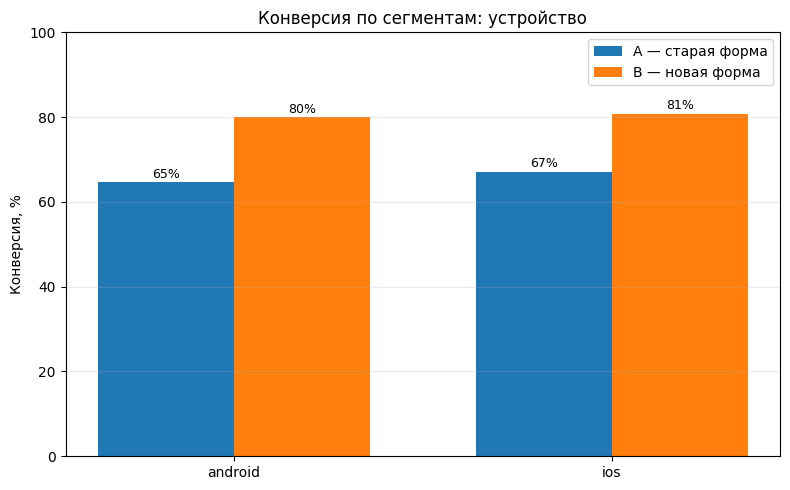

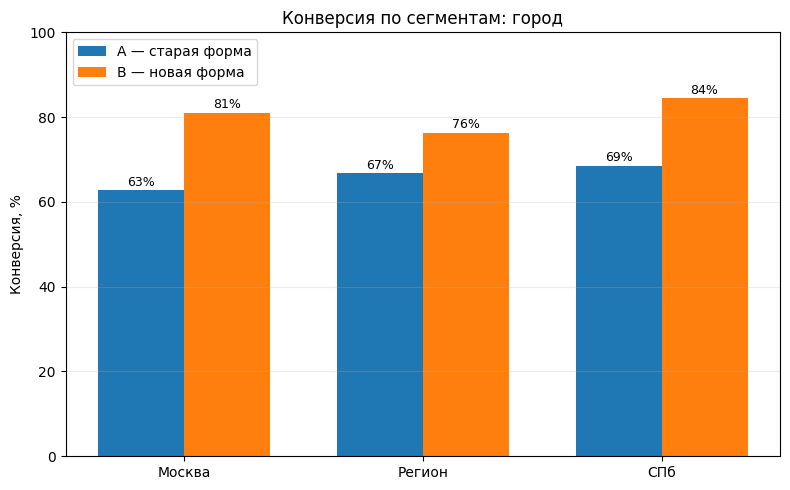

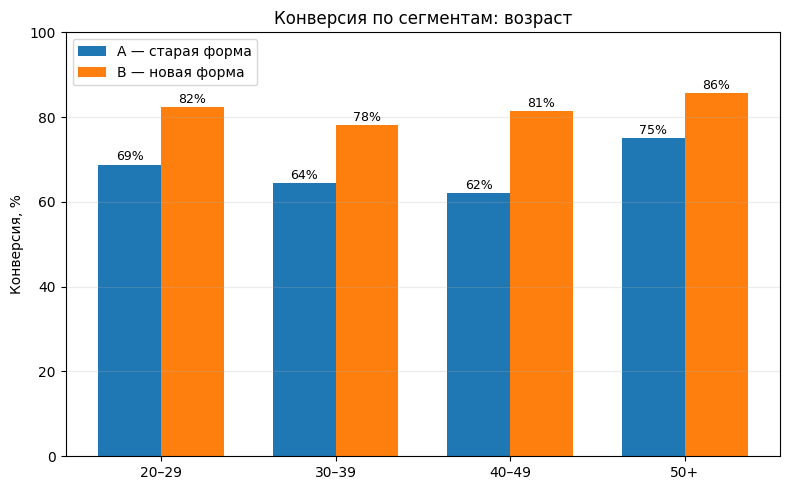

In [4]:
for dimension in segment_results['dimension'].drop_duplicates():
    d=segment_results[segment_results.dimension==dimension].copy()
    d=d.sort_values('segment')
    x=np.arange(len(d)); width=.36
    fig,ax=plt.subplots(figsize=(max(8,len(d)*1.6),5))
    ax.bar(x-width/2,d.cr_A*100,width,label='A — старая форма')
    ax.bar(x+width/2,d.cr_B*100,width,label='B — новая форма')
    ax.set_xticks(x,d.segment)
    ax.set_ylabel('Конверсия, %')
    ax.set_title(f'Конверсия по сегментам: {dimension.lower()}')
    ax.set_ylim(0,100); ax.grid(axis='y',alpha=.25); ax.legend()
    for i,row in enumerate(d.itertuples()):
        ax.text(i-width/2,row.cr_A*100+1,f'{row.cr_A:.0%}',ha='center',fontsize=9)
        ax.text(i+width/2,row.cr_B*100+1,f'{row.cr_B:.0%}',ha='center',fontsize=9)
    plt.tight_layout(); plt.show()